# BILINGO: Arabic / English Customer Feedback Sentiment

UneeQ Interns · ML Task: Arabic/English Sentiment Classifier.

A company receives feedback in Arabic and English and wants it sorted into **positive, mixed or negative**. This notebook walks through the data, the cleaning, the two approaches (TF-IDF baseline and a fine-tuned transformer), and the error analysis. The heavy steps live in `src/` and are only loaded here.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.max_colwidth', 160)

## 1. Data

* **Arabic 100K Reviews** (hotels and books), already labelled Positive / Mixed / Negative.
* **Amazon Reviews, English** (products): 1-2 stars = negative, 3 = mixed, 4-5 = positive.
* **Arabic SHEIN reviews** (fashion, Gulf and Levantine dialect): kept apart as a *new-domain* test, never used for training.

Each language gets 5,000 / 1,000 / 1,000 reviews per class for train / validation / test, so both models and both languages are compared on equal terms.

In [2]:
train = pd.read_parquet('../data/processed/train.parquet')
test = pd.read_parquet('../data/processed/test.parquet')
print(train.shape, test.shape)
train.groupby(['lang','label']).size().unstack()

(30000, 5) (6000, 5)


label,mixed,negative,positive
lang,,,
ar,5000,5000,5000
en,5000,5000,5000


In [3]:
train.groupby('lang').sample(3, random_state=3)[['lang','label','text']]

,lang,label,text
23006,ar,mixed,انه كتاب يجععلك تعمل عقل و تفكر وتتأمل ما يحدث حولك فى حياتك الشخصية انتقالا الى أسرتك و مجتمعك ووطنك والعالم أجمع من حولك على الرغم من أن هناك موضوعتت لم ت...
9976,ar,mixed,يجذبني لساراماجو دائما تحليله النفسي العميق لشخصياته و لكن هذه الرواية استطرد في التحليل لدرجة تقترب من الملل.. بداية أحداث الرواية الفعلية من بعد صفحة و لك...
24428,ar,negative,أصبحت اللازانيا كثيرت البهار و الصلصة حامضة و البيتزا عارقه بالزيت هذا حال جميع المطاعم تبدأ بالتدني تدريجيا
15762,en,negative,"Firstly don't believe the rating here. Fakespot.com gives it a ranking of D, which means it is very likely that there are a lot of fake good reviews here. P..."
8919,en,positive,I really love the style of the pockets on the side!
9423,en,negative,I hoped these would work better for me... they fall out of my ears when trying to work out at my gym.


In [4]:
train.assign(words=train.text.str.split().str.len()).groupby('lang').words.describe()

,count,mean,std,min,25%,50%,75%,max
lang,,,,,,,,
ar,15000.0,55.371267,98.960229,1.0,13.0,26.0,58.0,1598.0
en,15000.0,34.977600,34.666055,2.0,13.0,25.0,45.0,644.0


## 2. Text cleaning

Two levels, because the two models need different things:

* **light clean** (transformer): remove URLs, HTML and mentions only. The pretrained tokenizer already understands punctuation, casing and emojis.
* **full clean** (TF-IDF): also unify Arabic spelling (أ/إ/آ → ا, ى → ي, ة → ه), strip diacritics and tatweel, lowercase English, squeeze repeated letters (رااااائع, sooo), turn *n't* into *not*, and keep emojis as tokens.

**Stopwords are kept on purpose.** *not*, *but*, *لا*, *لكن* are exactly the words that flip or split sentiment.

In [5]:
from src.clean import light_clean, full_clean, detect_language
for s in ['الفندق رااائع جداً 😍 والموظفين متعاونين!!!', "I didn't like it... Sooo disappointing http://x.co"]:
    print(detect_language(s), '|', light_clean(s), '|', full_clean(s))

ar | الفندق رااائع جداً 😍 والموظفين متعاونين!!! | الفندق راايع جدا 😍 والموظفين متعاونين ! !
en | I didn't like it... Sooo disappointing | i did not like it soo disappointing


## 3. Classical baseline

TF-IDF on word 1-2 grams and character 2-5 grams, then a linear classifier. Character n-grams matter for Arabic, where one word appears with many attached prefixes and suffixes (الفندق / بالفندق / وفندقكم). Candidates were compared on **validation** data:

In [6]:
pd.read_csv('../reports/baseline_selection.csv').round(3)

,model,val_macro_f1,fit_seconds,val_f1_ar,val_f1_en
0,Naive Bayes (words),0.634,3.6,0.624,0.644
1,Logistic regression C=0.5,0.657,21.0,0.669,0.645
2,Logistic regression C=1,0.657,32.2,0.669,0.645
3,Logistic regression C=2,0.652,32.1,0.663,0.640
4,Logistic regression C=4,0.646,39.1,0.661,0.632
5,Linear SVM C=0.1,0.652,15.0,0.665,0.639
6,Linear SVM C=0.3,0.649,16.2,0.661,0.638


## 4. Transformer

`xlm-roberta-base` is pretrained on 100 languages including Arabic and English. It was fine-tuned for 3 epochs on the **same 30K training reviews**; the best epoch was picked on validation. A third reference, a pretrained multilingual *tweet* sentiment model used as is (no training on our data), shows what you get without fine-tuning.

In [7]:
json.load(open('../models/transformer_info.json'))

{'base_model': 'xlm-roberta-base',
 'max_len': 192,
 'epochs': 3,
 'lr': 2e-05,
 'batch_size': 16,
 'train_minutes': 22.9,
 'best_val_macro_f1': 0.706560619387512,
 'val_by_epoch': [{'epoch': 1.0,
   'macro_f1': 0.6801370134677015,
   'loss': 0.6819348931312561},
  {'epoch': 2.0, 'macro_f1': 0.7056783777206189, 'loss': 0.6464844942092896},
  {'epoch': 3.0, 'macro_f1': 0.706560619387512, 'loss': 0.693376898765564}]}

## 5. Results on the test set

The test set was used once, after every choice was made on validation.

In [8]:
res = pd.read_csv('../reports/results.csv')
res.pivot(index='model', columns='subset', values='macro_f1').round(3)

subset,All test,Arabic,Arabic SHEIN (new domain),English
model,,,,
Fine-tuned XLM-RoBERTa,0.722,0.706,0.457,0.738
"Pretrained, no fine-tuning",0.496,0.464,0.506,0.530
TF-IDF + Logistic Regression,0.667,0.665,0.439,0.670


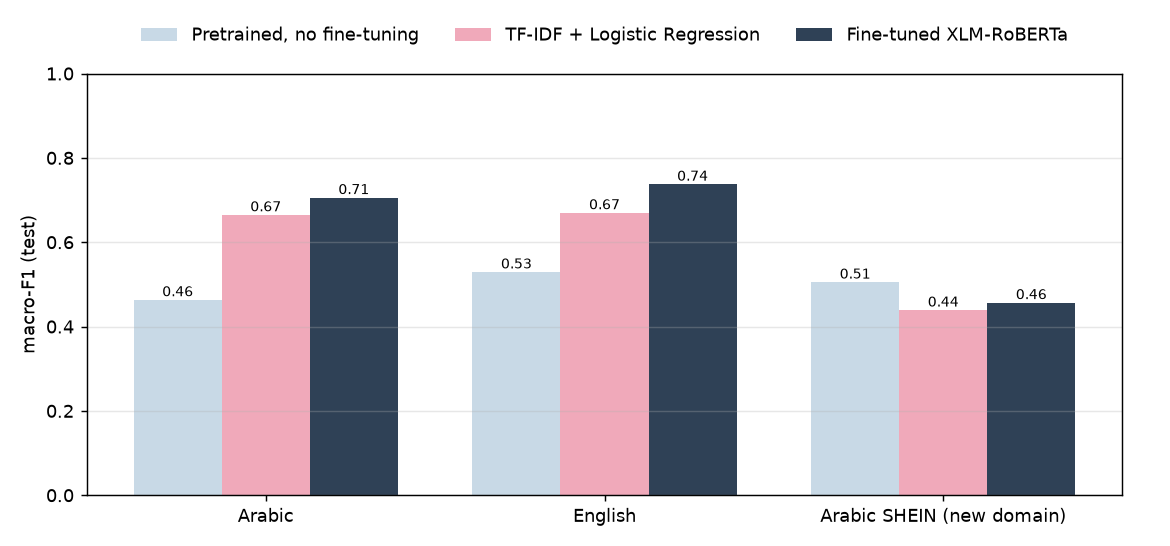

In [9]:
display(Image('../reports/figures/macro_f1.png'))

In [10]:
json.load(open('../reports/significance.json'))

{'all': {'diff': 0.05429596851030738,
  'ci95': [0.04200133281080321, 0.06731761498949776]},
 'ar': {'diff': 0.04086583796595056,
  'ci95': [0.023627883445646782, 0.05899353846454174]},
 'en': {'diff': 0.06770467577155515,
  'ci95': [0.050276074386199666, 0.0849022006892545]},
 'shein': {'diff': 0.0176874493326471,
  'ci95': [-0.0053265988262657, 0.03908786663910449]}}

**Is the comparison fair?** Same training data, same validation data for model selection, same test set, same label scheme. The paired bootstrap interval of the macro-F1 difference does not cross zero, so the gap is not luck of the sample.

## 6. Confusion matrices

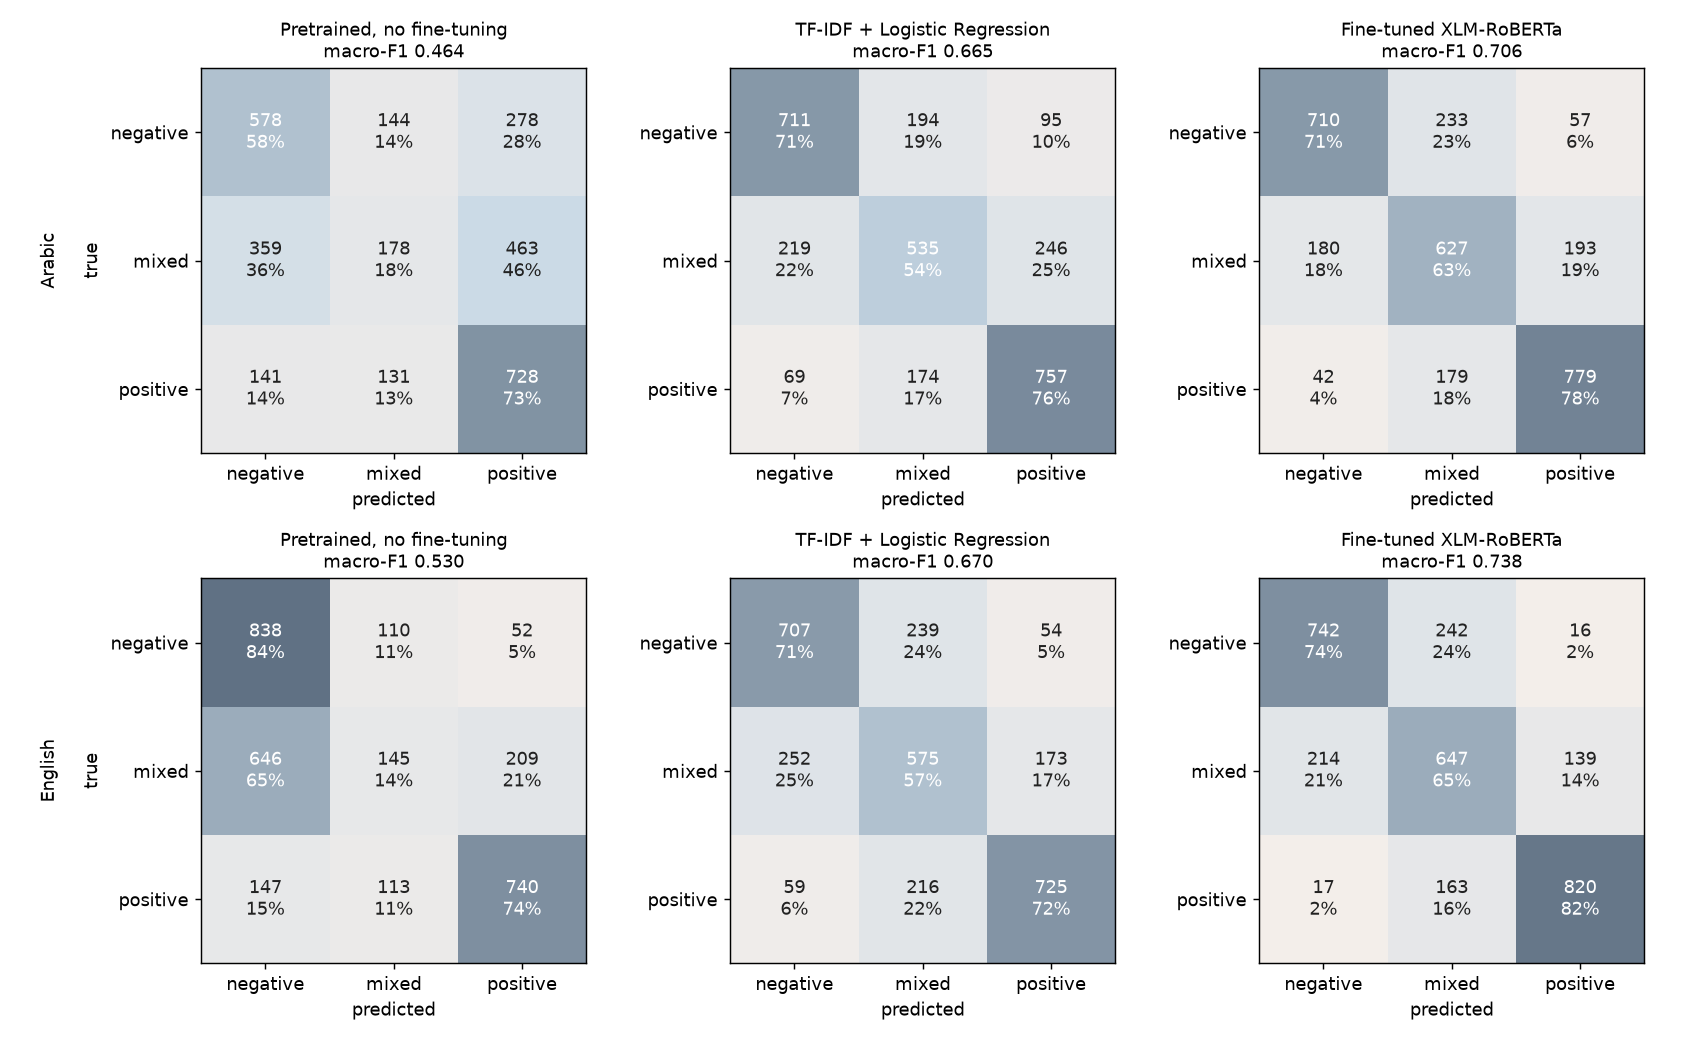

In [11]:
display(Image('../reports/figures/confusion_matrices.png'))

## 7. Error analysis

In [12]:
pd.read_csv('../reports/error_tags.csv').round(3)

,lang,tag,n,error_zero_shot,error_baseline,error_transformer
0,ar,all,3000,0.505,0.332,0.295
1,ar,has negation,1671,0.536,0.360,0.322
2,ar,has contrast (but / لكن),717,0.625,0.435,0.395
3,ar,short (< 8 words),348,0.480,0.250,0.195
4,ar,long (> 120 words),298,0.644,0.416,0.372
5,en,all,3000,0.426,0.331,0.264
6,en,has negation,1357,0.452,0.357,0.273
7,en,has contrast (but / لكن),1158,0.564,0.404,0.320
8,en,short (< 8 words),327,0.391,0.324,0.272
9,en,long (> 120 words),84,0.714,0.417,0.381


In [13]:
ex = pd.read_csv('../reports/error_examples.csv')
for kind in ex.kind.unique():
    print('\n=====', kind)
    display(ex[ex.kind == kind].groupby('lang').head(3)[['lang','label','baseline','transformer','text']])


===== both wrong, transformer confident


,lang,label,baseline,transformer,text
0,ar,negative,positive,positive,رائع . الاقامه بالفندق ممتازه بشكل عام ومن اكثر الاشياء روعه تعامل موضفي الاستقبال واخص بالذكر مازن القراش و عبدالرحمن الخضر فقد كانا رائعيين بالتعامل والاح...
1,ar,negative,positive,positive,رائع ... لا يتكلم فقط مع الملحدين. ولكن اى منا قد يوسوس له الشيطان باحد من هذة الاسئلة. اجاباته عقلانية ومقنعة بل و مذهلة فى صدقها و ترتيبها و سهولة طرحها ....
2,ar,negative,mixed,mixed,مرضي . نظافة الغرف. بعده عن الحرم المكي والاستقبال غير متعاون وبعض الغرف لا يوجد فيها ركن القهوه ولا يوجد تنظيف للغرف
15,en,mixed,positive,positive,I started taking these this past weekend and I have to say these are probably my favorite hydroxycut product yet! It usually takes me a while before feeling...
16,en,mixed,positive,positive,"They fit, are soft, and so far have gone through 3 wash and dry cycles without issue."
17,en,mixed,positive,positive,"I love this coloring book, i have it as a gift for my mom and this coloring book is so her. She's happy so im happy."



===== transformer fixed baseline


,lang,label,baseline,transformer,text
30,ar,positive,mixed,positive,جيد. الراحة..وجود سحور..تعامل الموظفين. سماع الاصوات خارج الغرفة صوت المصعد موقف الباصات بعيد عن الحرم خصوصا لمن معه كبار سن
31,ar,positive,mixed,positive,ممتاز. القرب من الاسواق وكذلك وجود جاكوزي في الغرفه. اسكان شركات فيها عماله من الفلبين تخرج من غرفهم رائحة طبخ سيئه
32,ar,positive,mixed,positive,جيد. ديكورات الغرفه. البساط غير نظيف بعض العاملين في الاستقبال غير مهذبلا توجد مواقف كافيه لجميع النزلاء واحتمال وجود موقف صعبه الواي فاي جدا شئ كأنه غير مو...
45,en,positive,negative,positive,Simply great! I don't need to waste paper towels no more when microwaving my food or waste wrapping foil in the fridge. They are very air-tight. Be Eco-frie...
46,en,positive,negative,positive,"I've been dealing with irritable bowel syndrome, and have taken this daily for about 2 months. One eye dropper full twice a day. My issue is almost complete..."
47,en,positive,negative,positive,"Great product: doesn't feel cheap, even if it is made from plastic, very easy settings, supports all possible functionality that you might need from metronome."



===== baseline right, transformer wrong


,lang,label,baseline,transformer,text
60,ar,mixed,mixed,positive,خالد . جيد. الخدمات عادية النظافة عادية
61,ar,mixed,mixed,positive,أعجبني أسلوبها جدا لدرجة أنهيت الرواية في يوم واحد ودون أن ينتابني الملل. وسأنتظر عملها القادم حتما
62,ar,positive,positive,negative,ليس في الإمكان ابدع مما كان
75,en,mixed,mixed,positive,"The are large but blend in well on a white wall. Despite the wall finish being uneven, the bumpers have stuck to it without fail. After a month no discolora..."
76,en,mixed,mixed,positive,About as comfortable as the original insoles that came with the boots
77,en,mixed,mixed,positive,I got this too be a quiet wireless printer to print from ipads etc.


In [14]:
shein = pd.read_csv('../reports/shein_predictions.csv')
pd.crosstab(shein.label, shein.transformer, normalize='index').round(2)

transformer,mixed,negative,positive
label,,,
mixed,0.46,0.38,0.16
negative,0.22,0.65,0.13
positive,0.31,0.22,0.47


See `reports/evaluation_report.md` for the discussion of these errors and the model's limitations.

## 8. Try it


In [15]:
from src.service import SentimentService
svc = SentimentService()
pd.DataFrame(svc.predict(['الخدمة ممتازة والتوصيل سريع', 'الموقع حلو بس الغرفة وسخة',
                          'Works as described, nothing special.', 'Oh great, it broke on day two.']))[['text','language','label','confidence']]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,text,language,label,confidence
0,الخدمة ممتازة والتوصيل سريع,ar,positive,0.981030
1,الموقع حلو بس الغرفة وسخة,ar,mixed,0.793211
2,"Works as described, nothing special.",en,positive,0.849078
3,"Oh great, it broke on day two.",en,negative,0.887751
